Training Shape: (60000, 785)
Testing Shape: (10000, 785)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.7534 - loss: 0.7454 - val_accuracy: 0.8215 - val_loss: 0.5214
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.8273 - loss: 0.4963 - val_accuracy: 0.8418 - val_loss: 0.4576
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.8421 - loss: 0.4523 - val_accuracy: 0.8511 - val_loss: 0.4313
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.8516 - loss: 0.4270 - val_accuracy: 0.8576 - val_loss: 0.4149
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.8580 - loss: 0.4084 - val_accuracy: 0.8609 - val_loss: 0.4028
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.8634 - loss: 0.3934 - val_accuracy: 0.8628 - val_loss: 0.3934
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.8678 - loss: 0.3806 - val_accuracy: 0.8637 - val_loss: 0.3851
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.8707 - loss: 0

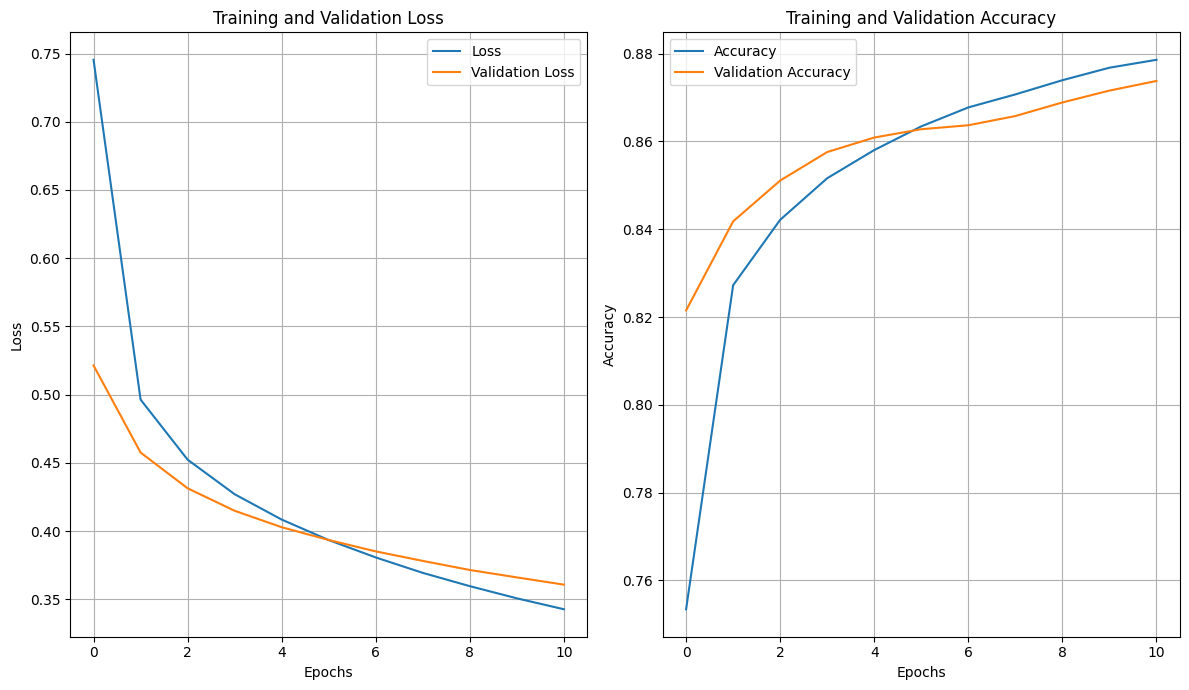

In [1]:

# a. Import necessary packages

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers

# b. Load training and testing data

train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

print("Training Shape:", train_data.shape)
print("Testing Shape:", test_data.shape)

# Separate features and labels

x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

# Normalize pixel values

x_train = x_train / 255.0
x_test = x_test / 255.0

# c. Define FNN architecture using Keras

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

# Compile the model

model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# d. Train the model using SGD

history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=11,
    validation_data=(x_test, y_test)
)

# e. Evaluate the network

loss, accuracy = model.evaluate(x_test, y_test)

print("Loss:", loss)
print("Accuracy:", accuracy)

# f. Plot training loss and accuracy

plt.figure(figsize=(12, 7))

# Training and validation loss

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.grid(True)
plt.legend()

# Training and validation accuracy

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()
